In [53]:
#Import pre-requisites libraries

In [54]:
# Import libraries for data processing
import numpy as np
import pandas as pd

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import ML algorithms
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

# Import tools for data splitting and preprocessing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Import evaluation metrics
from sklearn.metrics import (
  r2_score,
  mean_absolute_error,
  mean_squared_error
)

# Import joblib to save the trained model
import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [55]:
#Load data set

In [56]:
# Load the existing admission prediction dataset
df = pd.read_csv("../data/admission_predict.csv")

# Display the first five records
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [57]:
#Analyzing data set

In [58]:
# Load the existing admission prediction dataset
df = pd.read_csv("../data/admission_predict.csv")

# Display the first five records
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [59]:
#Data visulization

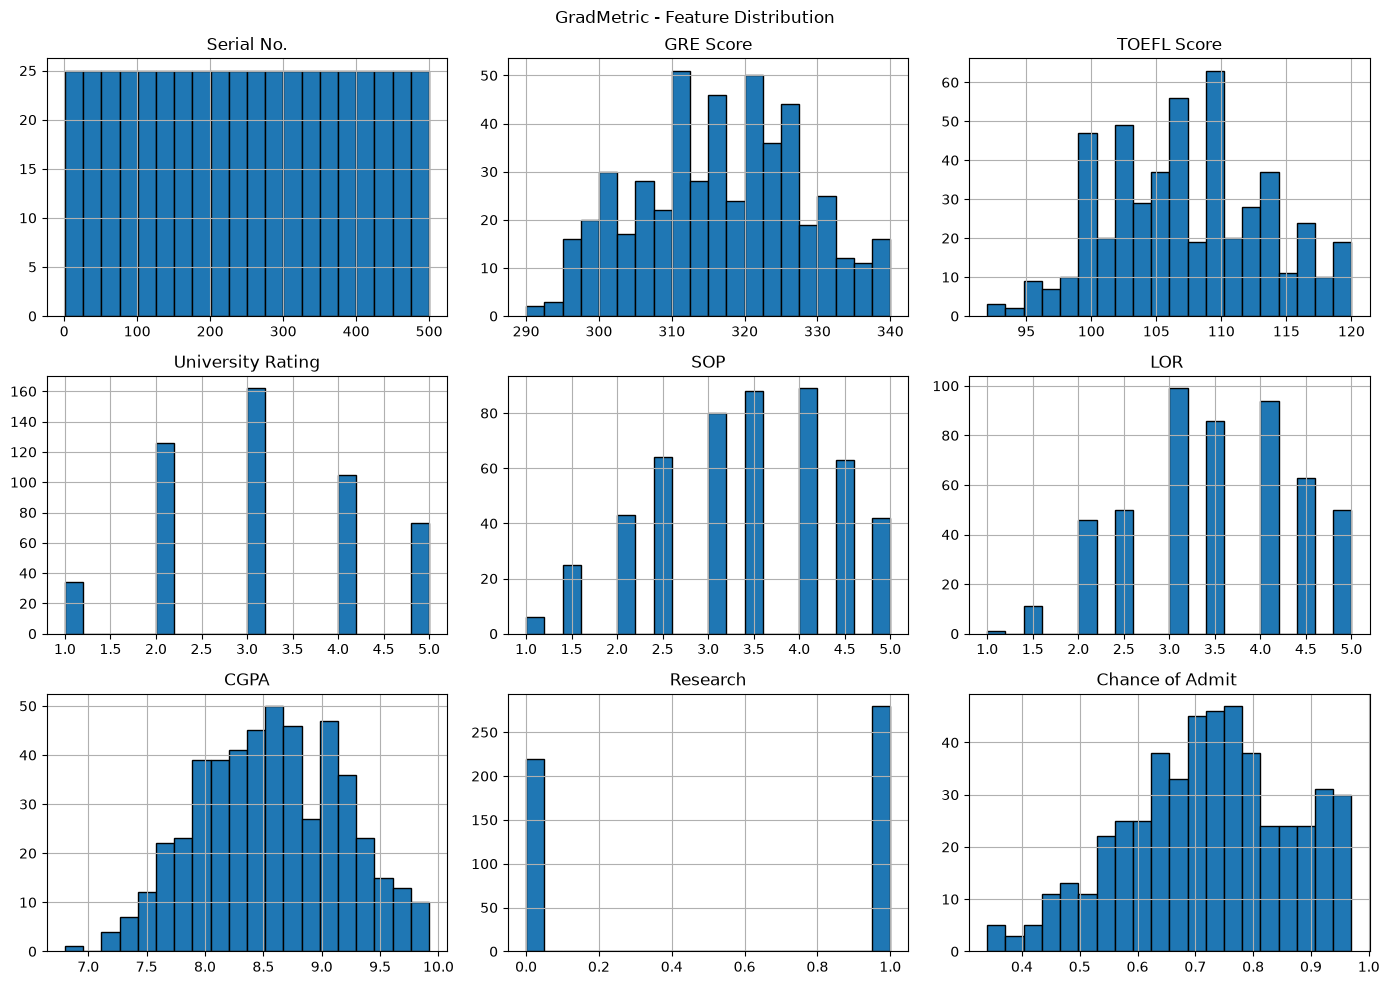

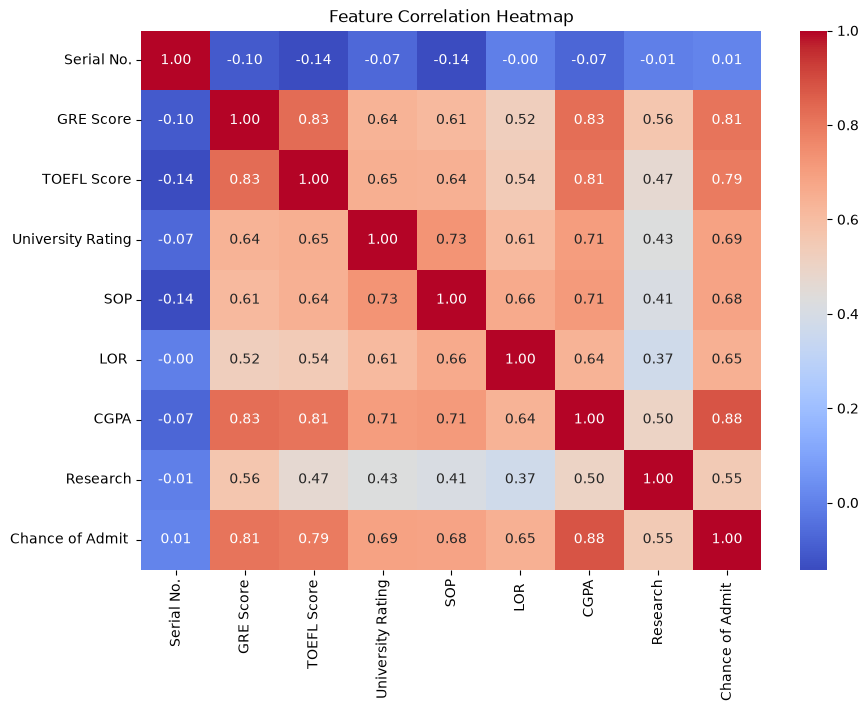

In [60]:
# Display distributions of all numerical features
df.hist(figsize=(14, 10), bins=20, edgecolor="black")

plt.suptitle("GradMetric - Feature Distribution")
plt.tight_layout()
plt.show()

# Display correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [61]:
#Data cleaning

In [62]:
# Rename columns to remove spaces and improve readability
df.rename(columns={
    "GRE Score": "GRE",
    "TOEFL Score": "TOEFL",
    "LOR ": "LOR",
    "Chance of Admit ": "Probability"
}, inplace=True)

# Remove Serial Number because it is not a useful prediction feature
df.drop(columns=["Serial No."], inplace=True)

# Remove duplicate records if any are found
df.drop_duplicates(inplace=True)

# Display cleaned dataset
df.head()

C:\Users\mahadev\AppData\Local\Temp\ipykernel_12732\1844871086.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
C:\Users\mahadev\AppData\Local\Temp\ipykernel_12732\1844871086.py:10: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Serial No."], inplace=True)
C:\Users\mahadev\AppData\Local\Temp\ipykernel_12732\1844871086.py:13: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


,GRE,TOEFL,University Rating,SOP,LOR,CGPA,Research,Probability
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72
3,322,110,3,3.5,2.5,8.67,1,0.80
4,314,103,2,2.0,3.0,8.21,0,0.65


In [63]:
# X contains independent variables used for prediction
X = df.drop(columns=["Probability"])

# y contains the target variable we want to predict
y = df["Probability"]

# Display the shapes
print("Input Features:", X.shape)
print("Target Variable:", y.shape)

Input Features: (500, 7)
Target Variable: (500,)


In [64]:
#Spliting dataset

In [65]:
# Divide data into training and testing sets
# 80% data is used for training
# 20% data is used for testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 400
Testing Records: 100


In [66]:
#creating models

In [67]:
# Create six regression models
# StandardScaler is used for algorithms sensitive to feature scales

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Lasso Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.01))
    ]),

    "SVR": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR())
    ]),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=5))
    ])
}

print("All six models created successfully!")

All six models created successfully!


In [68]:
#Training model and comparing 

In [69]:
# Create an empty list to store model performance
results = []

# Train each model and evaluate it
for name, model in models.items():

    # Train the model using training data
    model.fit(X_train, y_train)

    # Predict results using testing data
    predictions = model.predict(X_test)

    # Calculate R2 score
    score = r2_score(y_test, predictions)

    # Store the results
    results.append({
        "Model": name,
        "R2 Score": score
    })

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Sort models according to R2 score
results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
)

# Display model comparison
display(results_df)

,Model,R2 Score
0,Linear Regression,0.818843
1,Lasso Regression,0.813995
4,Random Forest,0.785984
5,KNN,0.780209
2,SVR,0.758938
3,Decision Tree,0.598729


In [70]:
# Compare models using 5-fold cross-validation
cv_results = []

for name, model in models.items():

    # Calculate R2 scores across five folds
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2"
    )

    # Store average cross-validation score
    cv_results.append({
        "Model": name,
        "Average CV R2": scores.mean()
    })

# Display cross-validation results
cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    by="Average CV R2",
    ascending=False
)

display(cv_df)

,Model,Average CV R2
0,Linear Regression,0.807902
1,Lasso Regression,0.801150
4,Random Forest,0.775948
5,KNN,0.775473
2,SVR,0.708038
3,Decision Tree,0.577573


In [71]:
#Select best model

In [72]:
# Select the model with the highest average cross-validation R2 score
best_model_name = cv_df.iloc[0]["Model"]

# Retrieve the selected model
best_model = models[best_model_name]

# Train the selected model on the complete training dataset
best_model.fit(X_train, y_train)

print("Selected Model:", best_model_name)

Selected Model: Linear Regression


In [73]:
# Generate predictions using the selected model
y_pred = best_model.predict(X_test)

# Calculate model evaluation metrics
r2 = r2_score(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

# Display evaluation results
print("Final Model:", best_model_name)

print("\nR2 Score:", round(r2, 4))
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))

Final Model: Linear Regression

R2 Score: 0.8188
MAE: 0.0427
MSE: 0.0037
RMSE: 0.0609


In [74]:
#visualizing actual vs predicition 

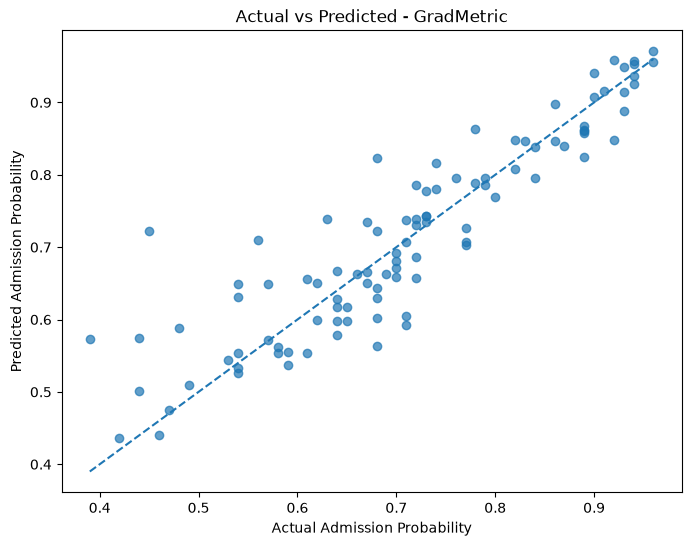

In [75]:
# Compare actual admission probabilities with predicted values
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

# Draw a reference line for perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Admission Probability")
plt.ylabel("Predicted Admission Probability")

plt.title("Actual vs Predicted - GradMetric")

plt.show()

In [76]:
#Saving model , so that if we pass input it will give us outupt ,"Creating Pipeline."

In [77]:
# Save the complete trained model pipeline
joblib.dump(
    best_model,
    "../models/gradmetric_model.pkl"
)

# Save the selected model name for reference
joblib.dump(
    best_model_name,
    "../models/model_name.pkl"
)

print("GradMetric model saved successfully!")

GradMetric model saved successfully!


In [78]:
#Tesing model with some input data

In [79]:
# Create sample student information
# Feature order must match the original training dataset

student_data = pd.DataFrame([{
    "GRE": 337,
    "TOEFL": 118,
    "University Rating": 4,
    "SOP": 4.5,
    "LOR": 4.5,
    "CGPA": 9.65,
    "Research": 1
}])

# Generate admission probability prediction
prediction = best_model.predict(student_data)[0]

# Display the prediction as a percentage
print("Predicted Admission Probability:",
      round(prediction * 100, 2), "%")

Predicted Admission Probability: 95.84 %


In [ ]:
#Completed model is working good.